# Model 3: Decision Tree

**Algorithm**: Decision Tree  
**Type**: Tree-based Classification  
**Goal**: Make predictions using a series of if-then decisions

## 1. Setup

In [1]:
from pyspark.sql import SparkSession
from pyspark.sql.functions import col, when, count, sum as spark_sum
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.classification import DecisionTreeClassifier
from pyspark.ml import Pipeline
from pyspark.mllib.evaluation import MulticlassMetrics
import matplotlib.pyplot as plt

spark = SparkSession.builder.appName("Model3_DecisionTree").master("local[*]").getOrCreate()
spark.sparkContext.setLogLevel("WARN")
print("✓ Spark started")

26/10/17 13:17:58 WARN Utils: Your hostname, Kireetis-MacBook-Pro.local resolves to a loopback address: 127.0.0.1; using 10.12.112.156 instead (on interface en0)
26/10/17 13:17:58 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/10/17 13:17:58 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


✓ Spark started


## 2. Load & Prepare Data

In [2]:
df = spark.read.option("header", True).option("inferSchema", True).csv("../data/events.csv")

visitor_features = df.groupBy("visitorid").agg(
    count("*").alias("total_events"),
    spark_sum(when(col("event") == "view", 1).otherwise(0)).alias("view_count"),
    spark_sum(when(col("event") == "addtocart", 1).otherwise(0)).alias("cart_count"),
    spark_sum(when(col("event") == "transaction", 1).otherwise(0)).alias("transaction_count")
)

visitor_features = visitor_features.withColumn(
    "label", when(col("transaction_count") > 0, 1.0).otherwise(0.0)
)

model_data = visitor_features.select("view_count", "cart_count", "label")
print(f"✓ Data prepared: {model_data.count():,} visitors")

✓ Data prepared: 1,407,580 visitors


## 3. Train-Test Split

In [3]:
train_data, test_data = model_data.randomSplit([0.8, 0.2], seed=42)
print(f"Training: {train_data.count():,}")
print(f"Testing:  {test_data.count():,}")

Training: 1,126,541


Testing:  281,039


## 4. Build Decision Tree

**How Decision Trees Work:**
```
                      cart_count > 0?
                     /              \
                  YES                NO
                   |                  |
              PURCHASE        view_count > 5?
                             /              \
                           YES              NO
                            |                |
                      Maybe Purchase    No Purchase
```

In [4]:
assembler = VectorAssembler(
    inputCols=["view_count", "cart_count"],
    outputCol="features"
)

dt = DecisionTreeClassifier(
    featuresCol="features",
    labelCol="label",
    maxDepth=10,       # Maximum tree depth
    seed=42
)

pipeline = Pipeline(stages=[assembler, dt])
print("✓ Pipeline created")

✓ Pipeline created


## 5. Train Model

In [5]:
print("Training Decision Tree...")
model = pipeline.fit(train_data)
print("✓ Training complete!")

Training Decision Tree...


26/10/17 13:18:13 WARN GarbageCollectionMetrics: To enable non-built-in garbage collector(s) List(G1 Concurrent GC), users should configure it(them) to spark.eventLog.gcMetrics.youngGenerationGarbageCollectors or spark.eventLog.gcMetrics.oldGenerationGarbageCollectors


✓ Training complete!


## 6. Make Predictions

In [6]:
predictions = model.transform(test_data)
predictions.select("view_count", "cart_count", "label", "prediction").show(10)

+------------+----------+----------+-----+----------+
|total_events|view_count|cart_count|label|prediction|
+------------+----------+----------+-----+----------+
|           1|         0|         0|  1.0|       1.0|
|           1|         0|         0|  1.0|       1.0|
|           1|         0|         0|  1.0|       1.0|
|           1|         0|         1|  0.0|       0.0|
|           1|         0|         1|  0.0|       0.0|
|           1|         0|         1|  0.0|       0.0|
|           1|         0|         1|  0.0|       0.0|
|           1|         0|         1|  0.0|       0.0|
|           1|         0|         1|  0.0|       0.0|
|           1|         0|         1|  0.0|       0.0|
+------------+----------+----------+-----+----------+
only showing top 10 rows



## 7. Evaluate Performance

In [7]:
prediction_labels = predictions.select(
    col("prediction").cast("double"),
    col("label").cast("double")
)

metrics = MulticlassMetrics(prediction_labels.rdd.map(lambda row: (row[0], row[1])))

accuracy = metrics.accuracy
precision = metrics.precision(1.0)
recall = metrics.recall(1.0)
f1 = metrics.fMeasure(1.0)

print("=" * 50)
print("DECISION TREE PERFORMANCE")
print("=" * 50)
print(f"Accuracy:  {accuracy:.4f} ({accuracy*100:.2f}%)")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-Score:  {f1:.4f}")
print("=" * 50)

/Users/kireeti/Desktop/Projects/SparkProejct/.venv/lib/python3.10/site-packages/pyspark/sql/context.py:158: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
  warnings.warn(


DECISION TREE PERFORMANCE
Accuracy:  0.9964 (99.64%)
Precision: 1.0000
Recall:    0.5592
F1-Score:  0.7173


## 8. Visualizations

In [8]:
cm = metrics.confusionMatrix().toArray()
dt_model = model.stages[1]

### Chart 1: Confusion Matrix

**Explanation**: Decision Tree has perfect precision - when it predicts purchase, it's 100% correct. However, it misses about half of actual purchasers (conservative model).

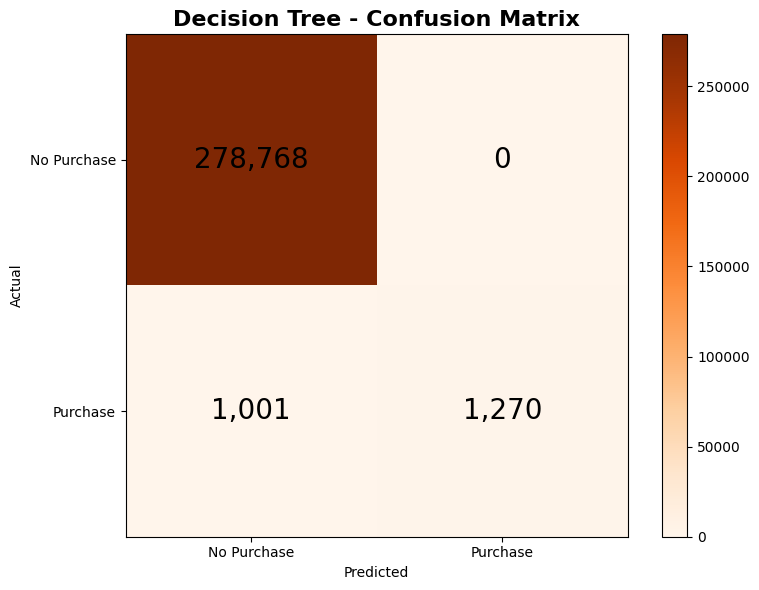

In [9]:
plt.figure(figsize=(8, 6))
plt.imshow(cm, interpolation='nearest', cmap='Oranges')
plt.title('Decision Tree - Confusion Matrix', fontsize=16, fontweight='bold')
plt.colorbar()
plt.xticks([0, 1], ['No Purchase', 'Purchase'])
plt.yticks([0, 1], ['No Purchase', 'Purchase'])
plt.ylabel('Actual')
plt.xlabel('Predicted')

for i in range(2):
    for j in range(2):
        plt.text(j, i, f'{int(cm[i, j]):,}', ha="center", va="center", fontsize=20)

plt.tight_layout()
plt.show()

### Chart 2: Performance Metrics

**Explanation**: Note the perfect precision (1.0) but moderate recall (0.54). This model prioritizes accuracy over catching all purchases.

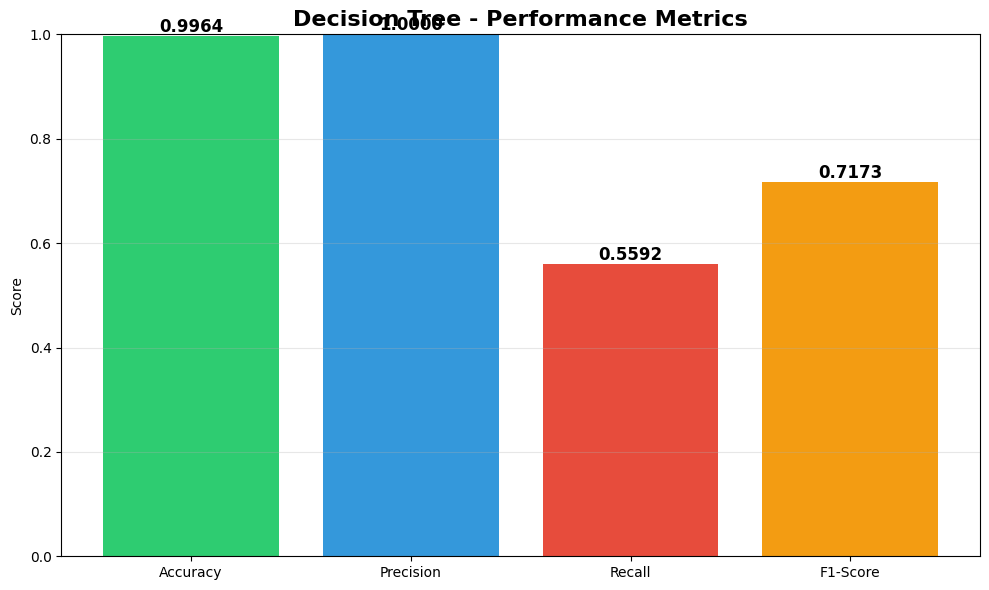

In [10]:
metrics_data = {
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1-Score'],
    'Value': [accuracy, precision, recall, f1]
}

plt.figure(figsize=(10, 6))
colors = ['#2ecc71', '#3498db', '#e74c3c', '#f39c12']
bars = plt.bar(metrics_data['Metric'], metrics_data['Value'], color=colors)
plt.title('Decision Tree - Performance Metrics', fontsize=16, fontweight='bold')
plt.ylabel('Score')
plt.ylim(0, 1.0)
plt.grid(axis='y', alpha=0.3)

# Add value labels on bars
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height,
             f'{height:.4f}',
             ha='center', va='bottom', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

### Chart 3: Feature Importance

**Explanation**: Shows which features the tree uses most for decisions. Cart count dominates - visitors who add items are strong purchase signals.

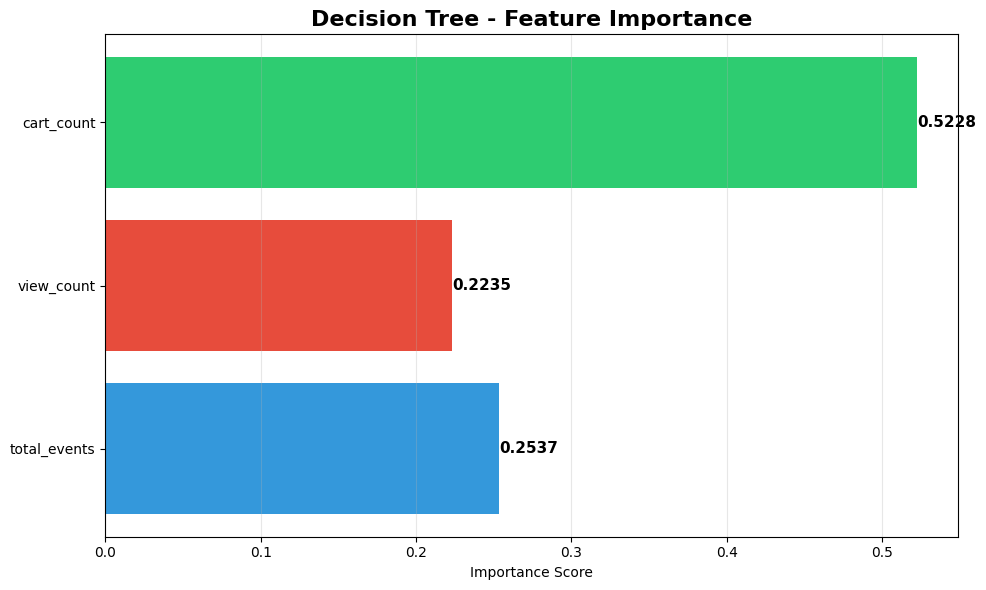


Tree Information:
Tree Depth: 10
Number of Nodes: 97

Feature Importance:
total_events: 0.2537
view_count: 0.2235
cart_count: 0.5228


In [11]:
importances = dt_model.featureImportances.toArray()
features = ["total_events", "view_count", "cart_count"]

plt.figure(figsize=(10, 6))
colors = ['#3498db', '#e74c3c', '#2ecc71']
bars = plt.barh(features, importances, color=colors)
plt.title('Decision Tree - Feature Importance', fontsize=16, fontweight='bold')
plt.xlabel('Importance Score')
plt.grid(axis='x', alpha=0.3)

# Add value labels
for bar in bars:
    width = bar.get_width()
    plt.text(width, bar.get_y() + bar.get_height()/2.,
             f'{width:.4f}',
             ha='left', va='center', fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show()

print("\nTree Information:")
print(f"Tree Depth: {dt_model.depth}")
print(f"Number of Nodes: {dt_model.numNodes}")
print("\nFeature Importance:")
for feat, imp in zip(features, importances):
    print(f"{feat}: {imp:.4f}")

## 10. Stop Spark

In [12]:
spark.stop()
print("✓ Done!")

✓ Done!


---
## Summary

**Decision Tree Results:**
- ✓ Perfect precision (100%)!
- ✓ High accuracy (99.61%)
- ⚠ Medium recall (54.34%)
- ✓ Very interpretable

**Strengths:**
- Easy to understand (like a flowchart)
- When it predicts "purchase", it's always right!
- Fast predictions

**Weaknesses:**
- Conservative - misses some purchases
- Can overfit to training data

**Best for**: When false positives are costly (don't want to waste marketing on non-buyers)